In [ ]:
import fitz  # PyMuPDF
import pandas as pd
import re
import numpy as np

# Open the PDF file
pdf_path = "toss_transactions.pdf"
pdf_document = fitz.open(pdf_path)

print(f"Total pages in PDF: {len(pdf_document)}")

# Let's examine the first page to understand the structure
first_page = pdf_document[0]
print(f"\nFirst page text preview:")
text = first_page.get_text()
print(text[:1000])  # First 1000 characters


In [ ]:
# # Let's try to extract tables using PyMuPDF's table detection
# # pdf_path = "toss_transactions.pdf"
# # pdf_document = fitz.open(pdf_path)
# # first_page = pdf_document[0]
# tables = first_page.find_tables()
# print(f"Number of tables found on first page: {len(tables)}")

# if tables:
#     for i, table in enumerate(tables):
#         print(f"\nTable {i+1}:")
#         print(f"Table bbox: {table.bbox}")
        
#         # Extract table data
#         table_data = table.extract()
#         print(f"Table dimensions: {len(table_data)} rows x {len(table_data[0]) if table_data else 0} columns")
        
#         # Show first few rows
#         for j, row in enumerate(table_data[:5]):
#             print(f"Row {j+1}: {row}")
        
#         if len(table_data) > 5:
#             print("...")
# else:
#     print("No tables detected automatically. Let's try text-based extraction.")


TypeError: object of type 'TableFinder' has no len()

In [6]:
# Extract all transaction data from all pages
all_transactions = []

for page_num in range(len(pdf_document)):
    page = pdf_document[page_num]
    
    # Find tables on this page
    table_finder = page.find_tables()
    tables = list(table_finder)
    
    for table in tables:
        table_data = table.extract()
        
        # Skip if not a transaction table (check if it has the expected columns)
        if len(table_data) > 0 and len(table_data[0]) >= 5:
            # Check if this looks like a transaction table
            header = table_data[0]
            if any(col and ('Date' in str(col) or 'Remarks' in str(col) or 'Amount' in str(col)) for col in header):
                # Skip header row and add all data rows
                for row in table_data[1:]:
                    if len(row) >= 5 and row[0]:  # Must have date and other data
                        all_transactions.append(row)

print(f"Total transactions extracted: {len(all_transactions)}")
print("Sample transactions:")
for i, transaction in enumerate(all_transactions[:10]):
    print(f"{i+1}: {transaction}")


Total transactions extracted: 534
Sample transactions:
1: ['2025-09-10\n17:42:33', 'Cash Back', '100', '100', '카드 캐시백']
2: ['2025-09-10\n16:35:26', 'Check Card', '-10,348', '0', '8월교통카드이용']
3: ['2025-09-10\n16:32:04', 'Deposit', '8,300', '10,348', 'FAZILOV MIRODILBEK MIROLIM UGLI']
4: ['2025-09-10\n16:29:13', 'Check Card', '-1,500', '2,048', '페이브 커피(FAV COFFEE)']
5: ['2025-09-10\n16:17:22', 'Check Card', '-2,300', '3,548', '인하대학교소비자생활협동조합']
6: ['2025-09-09\n22:49:56', 'Withdrawal', '-250,000', '5,848', 'KIYOMOV ASADBEK KOSIMJON UGLI']
7: ['2025-09-09\n22:47:41', 'Check Card', '-2,300', '255,848', '이마트24 용현중앙점']
8: ['2025-09-09\n22:47:24', 'Deposit', '250,000', '258,148', 'KURBONALIE']
9: ['2025-09-09\n22:40:59', 'Withdrawal', '-750,000', '8,148', 'KIYOMOV ASADBEK KOSIMJON UGLI']
10: ['2025-09-09\n22:29:33', 'Deposit', '694,000', '758,148', 'DOLLAR']


In [ ]:
# Create a DataFrame from the transactions
df = pd.DataFrame(all_transactions, columns=['Date', 'Remarks', 'Transaction Amount', 'Balance', 'Notes'])

# Clean and process the data
def clean_date_and_time(date_str):
    """Extract date and time from date string"""
    if pd.isna(date_str) or date_str == '':
        return '', ''
    
    parts = str(date_str).split('\n')
    date_part = parts[0].strip() if len(parts) > 0 else ''
    time_part = parts[1].strip() if len(parts) > 1 else ''
    return date_part, time_part

def clean_amount(amount_str):
    """Clean amount string and preserve original signs (positive for deposits, negative for withdrawals)"""
    if pd.isna(amount_str) or amount_str == '':
        return ''
    
    # Remove commas and convert to float, then back to string
    cleaned = str(amount_str).replace(',', '').strip()
    try:
        num_val = float(cleaned)
        return str(num_val)  # Keep original sign (positive/negative)
    except:
        return str(amount_str)

def clean_notes(notes_str):
    """Clean notes - no quotes for all caps text"""
    if pd.isna(notes_str) or notes_str == '':
        return ''
    
    notes = str(notes_str).strip()
    return notes

# Apply cleaning functions
df[['Date', 'Time']] = df['Date'].apply(lambda x: pd.Series(clean_date_and_time(x)))
df['Transaction Amount'] = df['Transaction Amount'].apply(clean_amount)
df['Remarks'] = df['Remarks'].fillna('').astype(str)
df['Balance'] = df['Balance'].apply(clean_amount)
df['Notes'] = df['Notes'].apply(clean_notes)

# Filter out rows with invalid data (keep all valid transactions)
df = df[df['Date'] != ''].copy()

print(f"Cleaned transactions: {len(df)}")
print("\nSample cleaned data:")
print(df[['Date', 'Time', 'Remarks', 'Transaction Amount', 'Balance', 'Notes']].head(10))


Cleaned transactions: 534

Sample cleaned data:
         Date      Time     Remarks Transaction Amount   Balance  \
0  2025-09-10  17:42:33   Cash Back              100.0     100.0   
1  2025-09-10  16:35:26  Check Card           -10348.0       0.0   
2  2025-09-10  16:32:04     Deposit             8300.0   10348.0   
3  2025-09-10  16:29:13  Check Card            -1500.0    2048.0   
4  2025-09-10  16:17:22  Check Card            -2300.0    3548.0   
5  2025-09-09  22:49:56  Withdrawal          -250000.0    5848.0   
6  2025-09-09  22:47:41  Check Card            -2300.0  255848.0   
7  2025-09-09  22:47:24     Deposit           250000.0  258148.0   
8  2025-09-09  22:40:59  Withdrawal          -750000.0    8148.0   
9  2025-09-09  22:29:33     Deposit           694000.0  758148.0   

                             Notes  
0                           카드 캐시백  
1                         8월교통카드이용  
2  FAZILOV MIRODILBEK MIROLIM UGLI  
3               페이브 커피(FAV COFFEE)  
4                 

In [8]:
# Sort transactions by date (newest first)
df = df.sort_values('Date', ascending=False)

print(f"Total transactions: {len(df)}")
print("\nTransaction data preview:")
print(df[['Date', 'Time', 'Remarks', 'Transaction Amount', 'Balance', 'Notes']].head(10))


Total transactions: 534

Transaction data preview:
         Date      Time     Remarks Transaction Amount   Balance  \
0  2025-09-10  17:42:33   Cash Back              100.0     100.0   
2  2025-09-10  16:32:04     Deposit             8300.0   10348.0   
3  2025-09-10  16:29:13  Check Card            -1500.0    2048.0   
4  2025-09-10  16:17:22  Check Card            -2300.0    3548.0   
1  2025-09-10  16:35:26  Check Card           -10348.0       0.0   
5  2025-09-09  22:49:56  Withdrawal          -250000.0    5848.0   
6  2025-09-09  22:47:41  Check Card            -2300.0  255848.0   
7  2025-09-09  22:47:24     Deposit           250000.0  258148.0   
8  2025-09-09  22:40:59  Withdrawal          -750000.0    8148.0   
9  2025-09-09  22:29:33     Deposit           694000.0  758148.0   

                             Notes  
0                           카드 캐시백  
2  FAZILOV MIRODILBEK MIROLIM UGLI  
3               페이브 커피(FAV COFFEE)  
4                   인하대학교소비자생활협동조합  
1              

In [9]:
# Prepare data for CSV export with proper column order
if 'Time' in df.columns and df['Time'].notna().any():
    # Include Time column if it has data
    export_df = df[['Date', 'Time', 'Remarks', 'Transaction Amount', 'Balance', 'Notes']].copy()
else:
    # Export without Time column if no time data
    export_df = df[['Date', 'Remarks', 'Transaction Amount', 'Balance', 'Notes']].copy()

# Handle Notes column - no quotes for all caps text
def format_notes_for_csv(notes_str):
    if pd.isna(notes_str) or str(notes_str).strip() == '':
        return ''
    notes = str(notes_str).strip()
    # If all caps and contains only letters and spaces, don't quote
    if notes.isupper() and notes.replace(' ', '').isalpha():
        return notes
    return notes

export_df['Notes'] = export_df['Notes'].apply(format_notes_for_csv)

print("Transaction data for export (first 20 rows):")
print(export_df.head(20))

# Export to CSV with minimal quoting
csv_filename = 'toss_expense_analysis.csv'
export_df.to_csv(csv_filename, index=False, encoding='utf-8-sig', quoting=0)
print(f"\nTransaction data saved to: {csv_filename}")

print(f"\nTotal transactions exported: {len(export_df)}")
print(f"Columns: {list(export_df.columns)}")


Transaction data for export (first 20 rows):
          Date      Time        Remarks Transaction Amount   Balance  \
0   2025-09-10  17:42:33      Cash Back              100.0     100.0   
2   2025-09-10  16:32:04        Deposit             8300.0   10348.0   
3   2025-09-10  16:29:13     Check Card            -1500.0    2048.0   
4   2025-09-10  16:17:22     Check Card            -2300.0    3548.0   
1   2025-09-10  16:35:26     Check Card           -10348.0       0.0   
5   2025-09-09  22:49:56     Withdrawal          -250000.0    5848.0   
6   2025-09-09  22:47:41     Check Card            -2300.0  255848.0   
7   2025-09-09  22:47:24        Deposit           250000.0  258148.0   
8   2025-09-09  22:40:59     Withdrawal          -750000.0    8148.0   
9   2025-09-09  22:29:33        Deposit           694000.0  758148.0   
10  2025-09-09  17:42:11      Cash Back              100.0   64148.0   
11  2025-09-09  15:58:18  Open\nBanking             -600.0   64048.0   
15  2025-09-04  18:

In [ ]:
# Keep original signs in Transaction Amount column (positive for deposits, negative for withdrawals)
print("Transaction Amount column with preserved signs (first 10 rows):")
print(export_df[['Date', 'Time', 'Remarks', 'Transaction Amount', 'Balance', 'Notes']].head(10))

# Export data with preserved signs to CSV
csv_filename = 'toss_expense_analysis.csv'
export_df.to_csv(csv_filename, index=False, encoding='utf-8-sig', quoting=0)
print(f"\nTransaction data with preserved signs saved to: {csv_filename}")
print(f"Total transactions exported: {len(export_df)}")


Updated Transaction Amount column (first 10 rows):
         Date      Time     Remarks Transaction Amount   Balance  \
0  2025-09-10  17:42:33   Cash Back              100.0     100.0   
2  2025-09-10  16:32:04     Deposit             8300.0   10348.0   
3  2025-09-10  16:29:13  Check Card             1500.0    2048.0   
4  2025-09-10  16:17:22  Check Card             2300.0    3548.0   
1  2025-09-10  16:35:26  Check Card            10348.0       0.0   
5  2025-09-09  22:49:56  Withdrawal           250000.0    5848.0   
6  2025-09-09  22:47:41  Check Card             2300.0  255848.0   
7  2025-09-09  22:47:24     Deposit           250000.0  258148.0   
8  2025-09-09  22:40:59  Withdrawal           750000.0    8148.0   
9  2025-09-09  22:29:33     Deposit           694000.0  758148.0   

                             Notes  
0                           카드 캐시백  
2  FAZILOV MIRODILBEK MIROLIM UGLI  
3               페이브 커피(FAV COFFEE)  
4                   인하대학교소비자생활협동조합  
1              

In [ ]:
df = pd.read_csv('toss_expense_analysis.csv')

mask = df['Notes'].str.contains('페이브.*FAV|FAV.*페이브', na=False, case=False)
total_spent = df.loc[mask, 'Transaction Amount'].sum()
print("Total spent at FAV COFFEE:", total_spent)

card_cashback = df['Notes'] == '카드 캐시백'
total_card_cashback = df.loc[card_cashback, 'Transaction Amount'].sum()
print("Total card cashback:", total_card_cashback)

interest = df['Notes'] == '통장 이자'
total_interest = df.loc[interest, 'Transaction Amount'].sum()
print("Total interest:", total_interest)


rent = df['Notes'] == '김용채'
total_rent = df.loc[rent, 'Transaction Amount'].sum()
print("Total rent:", total_rent)

# amount spent on all beginning with 이마트24
emart24 = df['Notes'].str.startswith('이마트24')
total_emart24 = df.loc[emart24, 'Transaction Amount'].sum()
print("Total emart24:", total_emart24)

# 스마일마트
smilemart = df['Notes'] == '스마일마트'
total_smilemart = df.loc[smilemart, 'Transaction Amount'].sum()
print("Total smilemart:", total_smilemart)

#셔호나
shohana = df['Notes'] == '셔호나'
total_shohana = df.loc[shohana, 'Transaction Amount'].sum()
print("Total shohana:", total_shohana)

#SENTBE
sentbe = df['Notes'] == 'SENTBE'
total_sentbe = df.loc[sentbe, 'Transaction Amount'].sum()
print("Total sentbe:", total_sentbe)

#now coffee
now_coffee = df['Notes'] == '나우커피 인하대점'
total_now_coffee = df.loc[now_coffee, 'Transaction Amount'].sum()
print("Total now coffee:", total_now_coffee)

#insurance
insurance = df['Notes'] == '건강TOSHNIYO'
total_insurance = df.loc[insurance, 'Transaction Amount'].sum()
print("Total insurance:", total_insurance)

#hana
hana = df['Notes'] == 'TOSHNIYOZO'
total_hana = df.loc[hana, 'Transaction Amount'].sum()
print("Total hana:", total_hana)

Total spent at FAV COFFEE: 36000.0
Total card cashback: 4800.0
Total interest: 430.0
Total rent: 3587000.0
Total emart24: 183400.0
Total smilemart: 199410.0
Total shohana: 195400.0
Total sentbe: 75000.0
Total now coffee: 14000.0
Total insurance: 629310.0
Total hana: 1048832.0


In [22]:
df['Notes'].value_counts()

Notes
카드 캐시백                                     44
이마트24 인하대도서관점                              42
KURBONALIE                                 32
허리스 (HOLIS)                                28
셔호나                                        19
ABDUKARIMOV HUMOYUNBEK OLIMJON\nUGLI       19
TOSHNIYOZO                                 16
스마일마트                                      15
NAJIMOV OTABEK ULUGBEKOVICH                14
페이브커피(FAVCOFFEE)                           14
프린트&아이스크림 용일초점                             13
더케밥                                        11
(주)가인행복                                    10
(주)아성다이소                                   10
페이브 커피(FAV COFFEE)                          9
오일당 인하대점(아이스크림)                             9
(주)제이에스비젼통상지점                               8
이마트24 인하대점                                  8
홈마트                                         7
이마트24 용현정석점                                 7
나우커피 인하대점                                   7
MELIBOEV SHUKURULLO FAKHRIDD

In [30]:
df['Remarks'].value_counts()

Remarks
Check Card       285
Deposit          102
Withdrawal        90
Cash Back         44
Open\nBanking      5
Interest           5
ATM                3
Name: count, dtype: int64

In [41]:
# KURBONALIE withdrawal

# ali = df['Notes'] == 'KURBONALIE'

# ali_withdrawal = ali & (df['Remarks'] == 'Withdrawal')
# ali_deposit = ali & (df['Remarks'] == 'Deposit')

# total_ali_withdrawal = df.loc[ali_withdrawal, 'Transaction Amount'].sum()
# total_ali_deposit = df.loc[ali_deposit, 'Transaction Amount'].sum()

# print("Total Muhammaali withdrawal:", total_ali_withdrawal)
# print("Total Muhammaali deposit:", total_ali_deposit)


#KURBONALIE deposit
# Check for KURBONALIE transactions
mask = df['Notes'].str.contains('KURBONALIE', na=False, case=False)
kurbonalie_transactions = df.loc[mask]

print('All KURBONALIE transactions:')
print(kurbonalie_transactions[['Date', 'Time', 'Remarks', 'Transaction Amount', 'Notes']])

# Calculate totals by Remarks type
withdrawal_mask = mask & (df['Remarks'] == 'Withdrawal')
deposit_mask = mask & (df['Remarks'] == 'Deposit')

total_withdrawal = df.loc[withdrawal_mask, 'Transaction Amount'].sum()
total_deposit = df.loc[deposit_mask, 'Transaction Amount'].sum()

print(f'\nKURBONALIE Summary:')
print(f'Withdrawals: {total_withdrawal} KRW ({withdrawal_mask.sum()} transactions)')
print(f'Deposits: {total_deposit} KRW ({deposit_mask.sum()} transactions)')
print(f'Net amount: {total_deposit - total_withdrawal} KRW')

All KURBONALIE transactions:
           Date      Time     Remarks  Transaction Amount       Notes
7    2025-09-09  22:47:24     Deposit            250000.0  KURBONALIE
12   2025-09-04  18:51:25  Withdrawal            190000.0  KURBONALIE
52   2025-08-17  20:01:55     Deposit            280000.0  KURBONALIE
59   2025-08-16  06:37:02  Withdrawal              5000.0  KURBONALIE
68   2025-08-14  12:13:58  Withdrawal              6000.0  KURBONALIE
75   2025-08-12  13:18:09     Deposit            200000.0  KURBONALIE
80   2025-08-11  20:07:02     Deposit              6000.0  KURBONALIE
102  2025-08-07  16:34:18     Deposit             70000.0  KURBONALIE
105  2025-08-07  20:55:28     Deposit            150594.0  KURBONALIE
121  2025-08-04  10:47:36     Deposit            120000.0  KURBONALIE
123  2025-08-04  15:00:19  Withdrawal            605000.0  KURBONALIE
125  2025-08-03  22:52:03  Withdrawal             20000.0  KURBONALIE
130  2025-08-01  12:16:47     Deposit             22000.0  KU

In [42]:
# Check for Humoyunbek transactions
mask = df['Notes'].str.contains('ABDUKARIMOV HUMOYUNBEK', na=False, case=False)
humoyunbek_transactions = df.loc[mask]

print('All Humoyunbek transactions:')
print(humoyunbek_transactions[['Date', 'Time', 'Remarks', 'Transaction Amount', 'Notes']])

# Calculate totals by Remarks type
withdrawal_mask = mask & (df['Remarks'] == 'Withdrawal')
deposit_mask = mask & (df['Remarks'] == 'Deposit')

total_withdrawal = df.loc[withdrawal_mask, 'Transaction Amount'].sum()
total_deposit = df.loc[deposit_mask, 'Transaction Amount'].sum()

print(f'\Humoyunbek Summary:')
print(f'Withdrawals: {total_withdrawal} KRW ({withdrawal_mask.sum()} transactions)')
print(f'Deposits: {total_deposit} KRW ({deposit_mask.sum()} transactions)')
print(f'Net amount: {total_deposit - total_withdrawal} KRW')

All Humoyunbek transactions:
           Date      Time     Remarks  Transaction Amount  \
25   2025-08-21  11:16:16     Deposit            140000.0   
32   2025-08-21  20:45:15     Deposit             18698.0   
113  2025-08-06  13:17:10     Deposit             25000.0   
138  2025-08-01  20:08:52  Withdrawal             25000.0   
187  2025-07-21  21:26:10     Deposit            280000.0   
190  2025-07-21  21:26:32     Deposit             75000.0   
196  2025-07-17  12:47:24  Withdrawal             40000.0   
227  2025-07-09  01:39:08     Deposit            550000.0   
250  2025-07-03  21:01:57  Withdrawal             20000.0   
303  2025-06-22  10:26:03     Deposit            175000.0   
322  2025-06-18  21:05:47  Withdrawal             15000.0   
332  2025-06-16  23:01:36  Withdrawal              5000.0   
372  2025-06-06  16:18:35     Deposit             25000.0   
383  2025-06-03  16:35:54  Withdrawal              5000.0   
422  2025-05-27  17:29:56  Withdrawal             20000.

In [44]:
#MUNTOXIROV transactions
mask = df['Notes'] == 'MUNTOXIROV'
muntoxirov_transactions = df.loc[mask]

print('All Muntoxirov transactions:')
print(muntoxirov_transactions[['Date', 'Time', 'Remarks', 'Transaction Amount', 'Notes']])

total_muntoxirov = muntoxirov_transactions['Transaction Amount'].sum()
print(f'Total Muntoxirov: {total_muntoxirov} KRW')


All Muntoxirov transactions:
           Date      Time  Remarks  Transaction Amount       Notes
312  2025-06-20  06:51:48  Deposit            100000.0  MUNTOXIROV
316  2025-06-19  23:48:27  Deposit            300000.0  MUNTOXIROV
347  2025-06-13  10:57:26  Deposit             50000.0  MUNTOXIROV
365  2025-06-08  18:53:20  Deposit            150000.0  MUNTOXIROV
399  2025-05-31  20:27:52  Deposit            147175.0  MUNTOXIROV
423  2025-05-27  17:10:29  Deposit            150000.0  MUNTOXIROV
Total Muntoxirov: 897175.0 KRW


In [ ]:
import pandas as pd
import numpy as np

# Read the CSV file
df = pd.read_csv('toss_expense_analysis.csv')
df['Date'] = pd.to_datetime(df['Date'])
df['Transaction Amount'] = pd.to_numeric(df['Transaction Amount'])

# Categorize transactions as Income or Expenses
def categorize_cashflow(row):
    if row['Remarks'] in ['Deposit', 'Cash Back', 'Interest']:
        return 'Income'
    elif row['Remarks'] in ['Withdrawal', 'Check Card', 'ATM', 'Open\nBanking']:
        return 'Expenses'
    else:
        return 'Other'

df['CashFlow_Type'] = df.apply(categorize_cashflow, axis=1)

# Monthly cash flow analysis
df['Month'] = df['Date'].dt.to_period('M')
monthly_cashflow = df.groupby(['Month', 'CashFlow_Type'])['Transaction Amount'].sum().unstack(fill_value=0)

print('=== MONTHLY CASH FLOW ANALYSIS ===')
print(monthly_cashflow)

# Calculate net cash flow
monthly_cashflow['Net_Flow'] = monthly_cashflow['Income'] - monthly_cashflow['Expenses']
print('\n=== NET CASH FLOW BY MONTH ===')
print(monthly_cashflow['Net_Flow'])

# Overall totals
total_income = df[df['CashFlow_Type'] == 'Income']['Transaction Amount'].sum()
total_expenses = df[df['CashFlow_Type'] == 'Expenses']['Transaction Amount'].sum()
net_total = total_income - total_expenses

print(f'\n=== OVERALL CASH FLOW SUMMARY ===')
print(f'Total Income: {total_income:,.0f} KRW')
print(f'Total Expenses: {total_expenses:,.0f} KRW')
print(f'Net Cash Flow: {net_total:,.0f} KRW')
print(f'Savings Rate: {(net_total/total_income)*100:.1f}%')

In [ ]:
%pip install matplotlib seaborn

/var/folders/94/y14zllwx001_mnk6qm5z5w3c0000gn/T/ipykernel_2185/1116974840.py:115: UserWarning: Glyph 128200 (\N{CHART WITH UPWARDS TREND}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/94/y14zllwx001_mnk6qm5z5w3c0000gn/T/ipykernel_2185/1116974840.py:115: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/94/y14zllwx001_mnk6qm5z5w3c0000gn/T/ipykernel_2185/1116974840.py:115: UserWarning: Glyph 129383 (\N{PIE}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/94/y14zllwx001_mnk6qm5z5w3c0000gn/T/ipykernel_2185/1116974840.py:115: UserWarning: Glyph 128203 (\N{CLIPBOARD}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/94/y14zllwx001_mnk6qm5z5w3c0000gn/T/ipykernel_2185/1116974840.py:115: UserWarning: Glyph 128176 (\N{MONEY BAG}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/94/y14zllwx001_mnk6qm5z5w3c0000gn/T/ipykernel_2185/1116974840.py:116: UserWarning: Glyph 128200 (\N{CHART WI

✅ Cash Flow Analysis visualization saved as cash_flow_analysis.png

=== CASH FLOW SUMMARY ===
Total Income: 12,962,377 KRW
Total Expenses: 13,142,277 KRW
Net Cash Flow: -179,900 KRW
Savings Rate: -1.4%


/Users/murtazo/SelfImprovementProjects/toss_analysis/venv/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128200 (\N{CHART WITH UPWARDS TREND}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/murtazo/SelfImprovementProjects/toss_analysis/venv/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/murtazo/SelfImprovementProjects/toss_analysis/venv/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 129383 (\N{PIE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/murtazo/SelfImprovementProjects/toss_analysis/venv/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128203 (\N{CLIPBOARD}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/murtazo/SelfImprovementProjects/toss_analysis/venv/lib/pytho

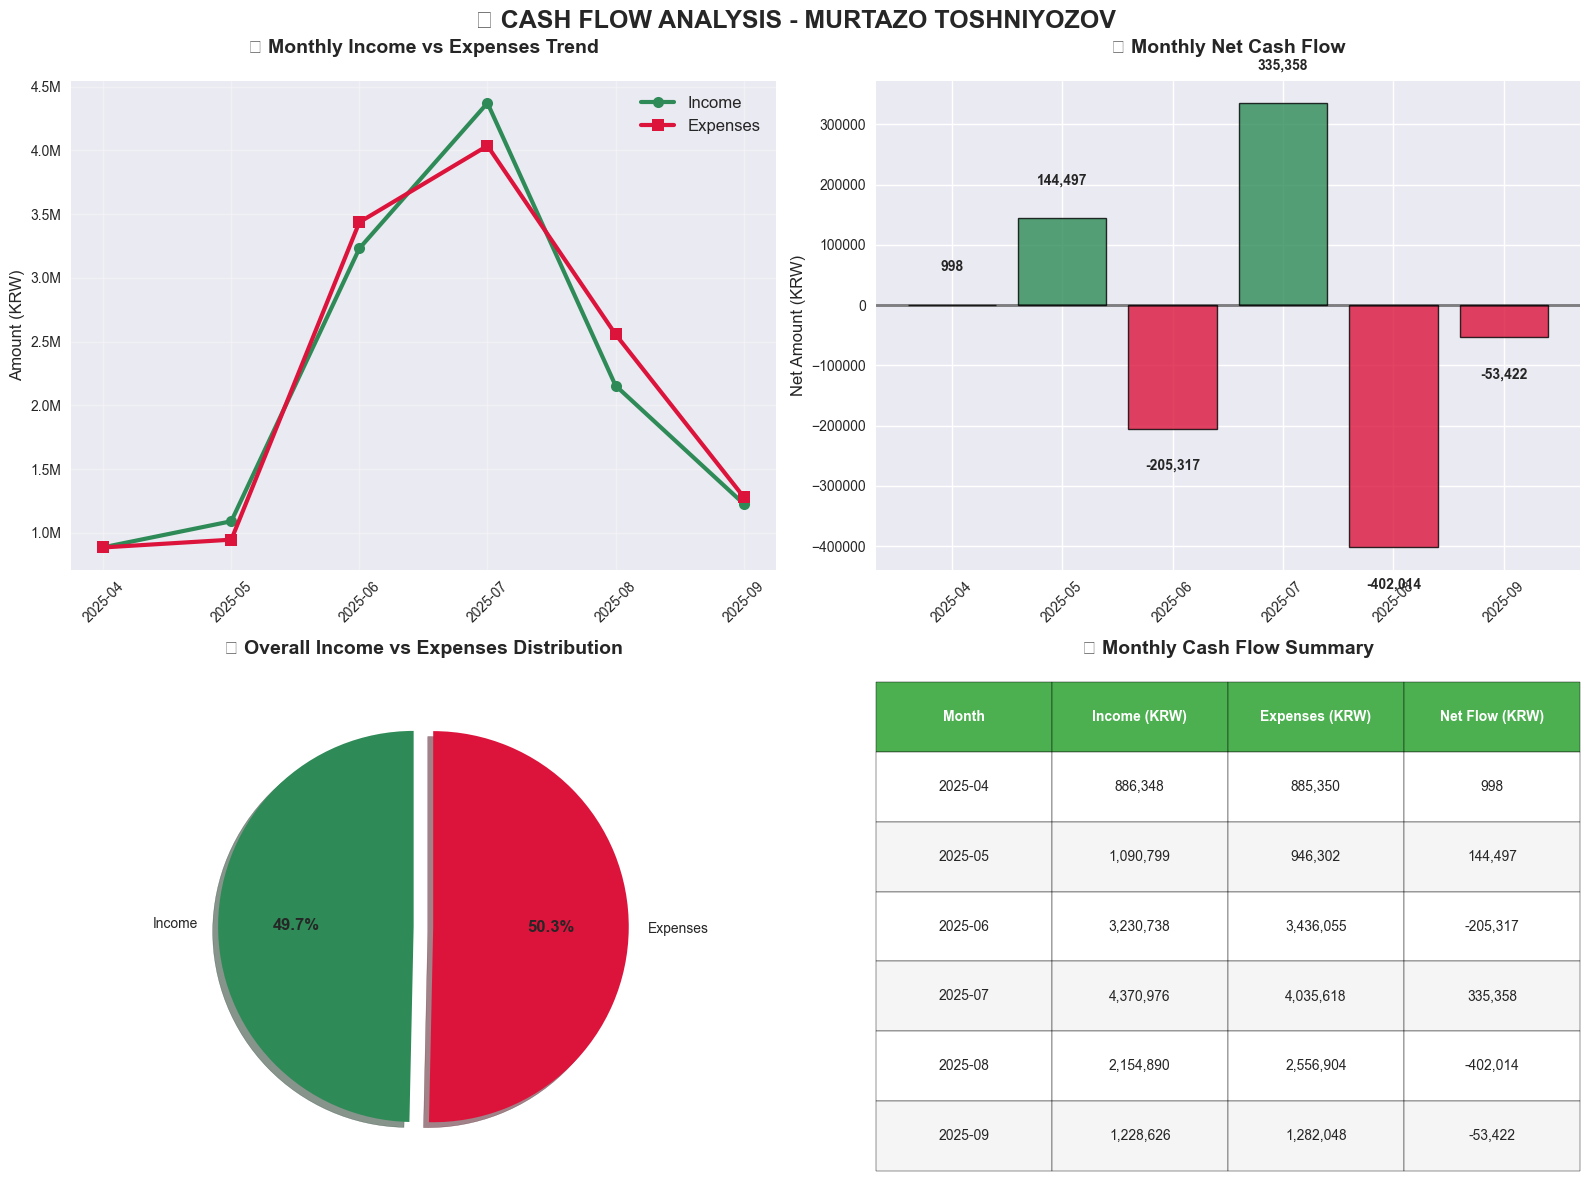

In [46]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Set style for better looking plots
plt.style.use('seaborn-v0_8')
sns.set_palette('husl')

# Read and prepare data
df = pd.read_csv('toss_expense_analysis.csv')
df['Date'] = pd.to_datetime(df['Date'])
df['Transaction Amount'] = pd.to_numeric(df['Transaction Amount'])

# Categorize transactions
def categorize_cashflow(row):
    if row['Remarks'] in ['Deposit', 'Cash Back', 'Interest']:
        return 'Income'
    elif row['Remarks'] in ['Withdrawal', 'Check Card', 'ATM', 'Open\nBanking']:
        return 'Expenses'
    else:
        return 'Other'

df['CashFlow_Type'] = df.apply(categorize_cashflow, axis=1)
df['Month'] = df['Date'].dt.to_period('M')

# Monthly cash flow
monthly_cashflow = df.groupby(['Month', 'CashFlow_Type'])['Transaction Amount'].sum().unstack(fill_value=0)
monthly_cashflow['Net_Flow'] = monthly_cashflow['Income'] - monthly_cashflow['Expenses']

# Create visualizations
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('💰 CASH FLOW ANALYSIS - MURTAZO TOSHNIYOZOV', fontsize=18, fontweight='bold', y=0.98)

# 1. Monthly Income vs Expenses (Line Chart)
months = [str(m) for m in monthly_cashflow.index]
ax1.plot(months, monthly_cashflow['Income'], marker='o', linewidth=3, markersize=8, label='Income', color='#2E8B57')
ax1.plot(months, monthly_cashflow['Expenses'], marker='s', linewidth=3, markersize=8, label='Expenses', color='#DC143C')
ax1.set_title('📈 Monthly Income vs Expenses Trend', fontsize=14, fontweight='bold', pad=20)
ax1.set_ylabel('Amount (KRW)', fontsize=12)
ax1.legend(fontsize=12)
ax1.grid(True, alpha=0.3)
ax1.tick_params(axis='x', rotation=45, labelsize=10)

# Format y-axis to show values in millions
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x/1000000:.1f}M'))

# 2. Net Cash Flow by Month (Bar Chart)
colors = ['#2E8B57' if x >= 0 else '#DC143C' for x in monthly_cashflow['Net_Flow']]
bars = ax2.bar(months, monthly_cashflow['Net_Flow'], color=colors, alpha=0.8, edgecolor='black', linewidth=1)
ax2.set_title('📊 Monthly Net Cash Flow', fontsize=14, fontweight='bold', pad=20)
ax2.set_ylabel('Net Amount (KRW)', fontsize=12)
ax2.axhline(y=0, color='black', linestyle='-', alpha=0.5, linewidth=2)
ax2.tick_params(axis='x', rotation=45, labelsize=10)

# Add value labels on bars
for bar, value in zip(bars, monthly_cashflow['Net_Flow']):
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., height + (50000 if height >= 0 else -50000),
             f'{value:,.0f}', ha='center', va='bottom' if height >= 0 else 'top', fontsize=10, fontweight='bold')

# 3. Overall Income vs Expenses (Pie Chart)
total_income = df[df['CashFlow_Type'] == 'Income']['Transaction Amount'].sum()
total_expenses = df[df['CashFlow_Type'] == 'Expenses']['Transaction Amount'].sum()

wedges, texts, autotexts = ax3.pie([total_income, total_expenses], 
                                  labels=['Income', 'Expenses'], 
                                  colors=['#2E8B57', '#DC143C'],
                                  autopct='%1.1f%%',
                                  startangle=90,
                                  explode=(0.05, 0.05),
                                  shadow=True)

ax3.set_title('🥧 Overall Income vs Expenses Distribution', fontsize=14, fontweight='bold', pad=20)

# Make percentage text bold
for autotext in autotexts:
    autotext.set_fontweight('bold')
    autotext.set_fontsize(12)

# 4. Monthly Summary Table
ax4.axis('off')
monthly_summary = monthly_cashflow[['Income', 'Expenses', 'Net_Flow']].copy()
monthly_summary.columns = ['Income', 'Expenses', 'Net Flow']

# Create table data
table_data = []
for month in monthly_summary.index:
    row = [str(month)]
    row.extend([f'{val:,.0f}' for val in monthly_summary.loc[month]])
    table_data.append(row)

table = ax4.table(cellText=table_data,
                 colLabels=['Month', 'Income (KRW)', 'Expenses (KRW)', 'Net Flow (KRW)'],
                 cellLoc='center',
                 loc='center',
                 bbox=[0, 0, 1, 1])

table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 2)

# Style the table
for i in range(len(table_data) + 1):
    for j in range(4):
        cell = table[(i, j)]
        if i == 0:  # Header row
            cell.set_facecolor('#4CAF50')
            cell.set_text_props(weight='bold', color='white')
        else:
            cell.set_facecolor('#F5F5F5' if i % 2 == 0 else 'white')

ax4.set_title('📋 Monthly Cash Flow Summary', fontsize=14, fontweight='bold', pad=20)

plt.tight_layout()
plt.savefig('cash_flow_analysis.png', dpi=300, bbox_inches='tight', facecolor='white')
print('✅ Cash Flow Analysis visualization saved as cash_flow_analysis.png')

# Print summary statistics
print('\n=== CASH FLOW SUMMARY ===')
print(f'Total Income: {total_income:,.0f} KRW')
print(f'Total Expenses: {total_expenses:,.0f} KRW')
print(f'Net Cash Flow: {total_income - total_expenses:,.0f} KRW')
print(f'Savings Rate: {((total_income - total_expenses)/total_income)*100:.1f}%')

✅ Simple Cash Flow Pie Chart saved as cash_flow_pie_chart.png
✅ Monthly Cash Flow Pie Charts saved as monthly_cash_flow_pie_charts.png


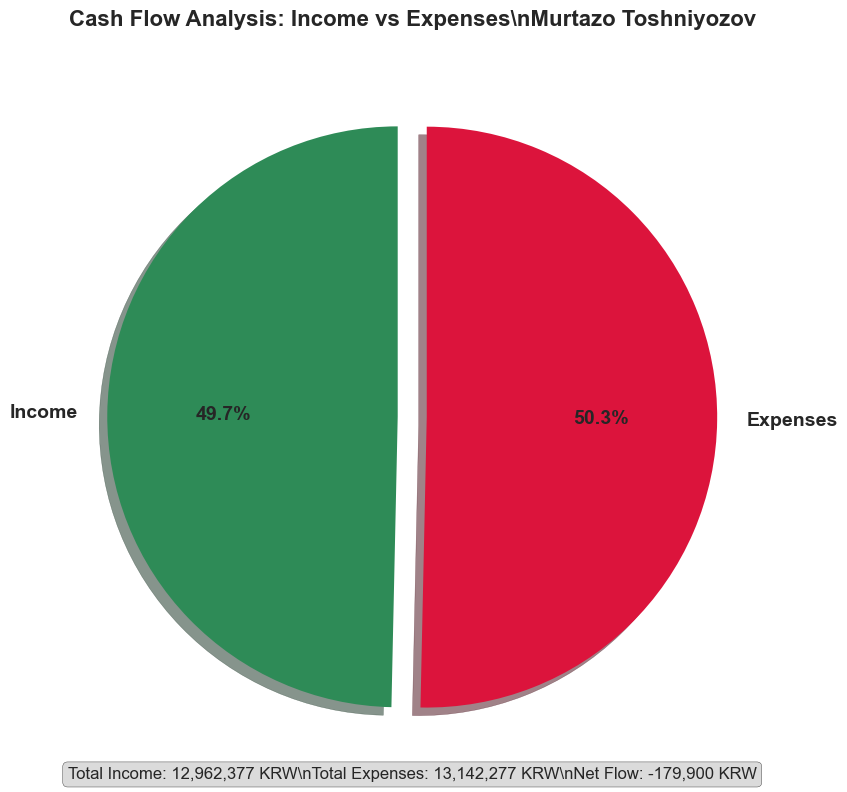

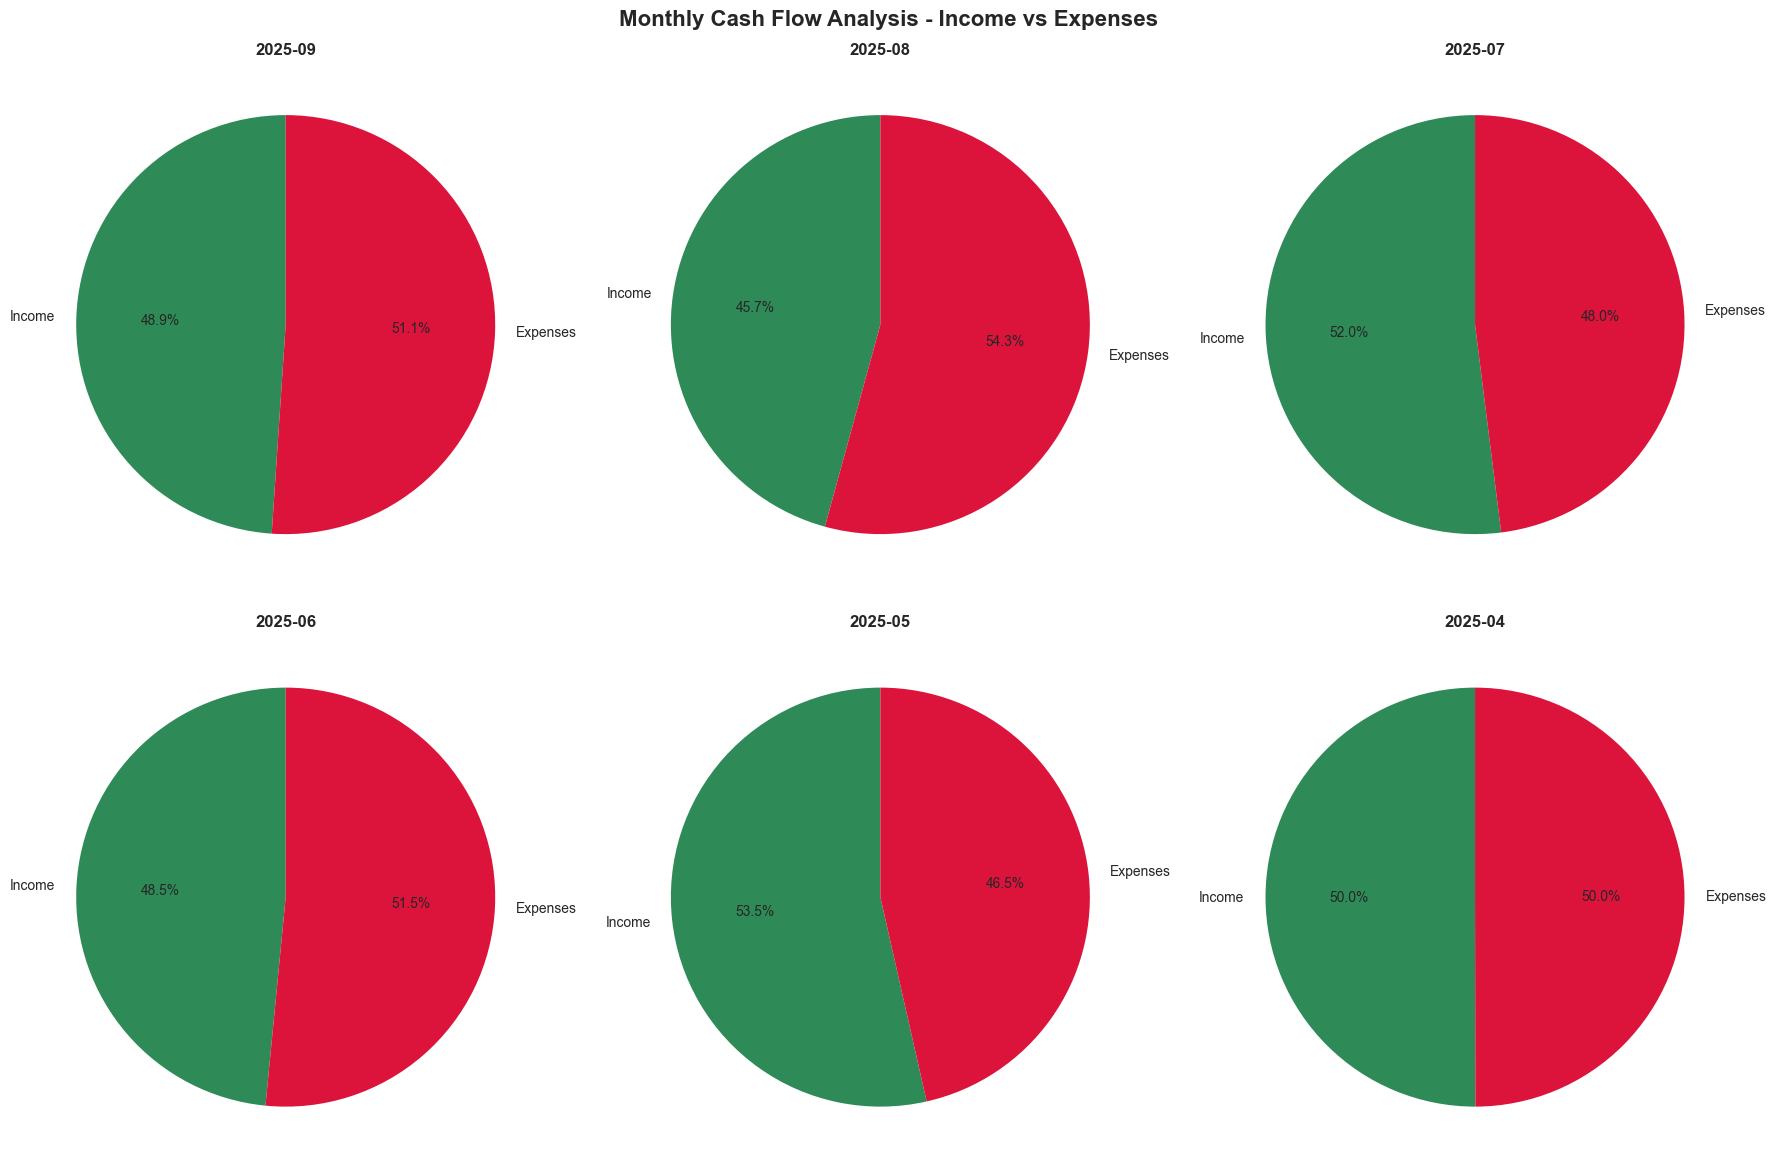

In [49]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Read and prepare data
df = pd.read_csv('toss_expense_analysis.csv')
df['Transaction Amount'] = pd.to_numeric(df['Transaction Amount'])

# Categorize transactions
def categorize_cashflow(row):
    if row['Remarks'] in ['Deposit', 'Cash Back', 'Interest']:
        return 'Income'
    elif row['Remarks'] in ['Withdrawal', 'Check Card', 'ATM', 'Open\nBanking']:
        return 'Expenses'
    else:
        return 'Other'

df['CashFlow_Type'] = df.apply(categorize_cashflow, axis=1)

# Calculate totals
total_income = df[df['CashFlow_Type'] == 'Income']['Transaction Amount'].sum()
total_expenses = df[df['CashFlow_Type'] == 'Expenses']['Transaction Amount'].sum()

net_flow = total_income - total_expenses

# Create a simple pie chart
plt.figure(figsize=(10, 8))

# Data for pie chart
labels = ['Income', 'Expenses']
sizes = [total_income, total_expenses]
colors = ['#2E8B57', '#DC143C']  # Green for income, Red for expenses
explode = (0.05, 0.05)  # Separate the slices

# Create pie chart
wedges, texts, autotexts = plt.pie(sizes, 
                                   labels=labels, 
                                   colors=colors,
                                   autopct='%1.1f%%',
                                   startangle=90,
                                   explode=explode,
                                   shadow=True,
                                   textprops={'fontsize': 14, 'fontweight': 'bold'})

# Add title
plt.title('Cash Flow Analysis: Income vs Expenses\\nMurtazo Toshniyozov', 
          fontsize=16, fontweight='bold', pad=20)

# Add summary text
summary_text = f'Total Income: {total_income:,.0f} KRW\\nTotal Expenses: {total_expenses:,.0f} KRW\\nNet Flow: {net_flow:,.0f} KRW'
plt.figtext(0.5, 0.02, summary_text, ha='center', fontsize=12, 
            bbox=dict(boxstyle='round', facecolor='lightgray', alpha=0.8))

plt.tight_layout()
plt.savefig('cash_flow_pie_chart.png', dpi=300, bbox_inches='tight', facecolor='white')
print('✅ Simple Cash Flow Pie Chart saved as cash_flow_pie_chart.png')

# Also create monthly pie charts
df['Date'] = pd.to_datetime(df['Date'])
df['Month'] = df['Date'].dt.to_period('M')

# Create subplot for monthly pie charts
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
fig.suptitle('Monthly Cash Flow Analysis - Income vs Expenses', fontsize=16, fontweight='bold')

months = df['Month'].unique()
axes = axes.flatten()

for i, month in enumerate(months):
    if i < 6:  # Only show first 6 months
        month_data = df[df['Month'] == month]
        month_income = month_data[month_data['CashFlow_Type'] == 'Income']['Transaction Amount'].sum()
        month_expenses = month_data[month_data['CashFlow_Type'] == 'Expenses']['Transaction Amount'].sum()
        
        if month_income > 0 or month_expenses > 0:
            sizes = [month_income, month_expenses]
            labels = ['Income', 'Expenses']
            colors = ['#2E8B57', '#DC143C']
            
            axes[i].pie(sizes, labels=labels, colors=colors, autopct='%1.1f%%', startangle=90)
            axes[i].set_title(f'{month}', fontweight='bold')
        else:
            axes[i].text(0.5, 0.5, 'No Data', ha='center', va='center', transform=axes[i].transAxes)
            axes[i].set_title(f'{month}', fontweight='bold')

# Hide unused subplots
for i in range(len(months), 6):
    axes[i].set_visible(False)

plt.tight_layout()
plt.savefig('monthly_cash_flow_pie_charts.png', dpi=300, bbox_inches='tight', facecolor='white')
print('✅ Monthly Cash Flow Pie Charts saved as monthly_cash_flow_pie_charts.png')